# Rain Prediction — XGBoost v2 (regularized + feature-engineered)

Follow-up to `XGBoost.ipynb` / [`XGB_experiments.md`](./XGB_experiments.md) (EXP-2026-06-15-001).
That run found a tuned XGBoost tied the logistic baseline at **test F1 = 0.65** while
**memorizing the training set** (train F1 ≈ 1.0, CV F1 ≈ 0.617). This notebook tests three
follow-up hypotheses:

1. **Regularization + early stopping** shrinks the train↔CV gap without hurting (possibly
   helping) test F1.
2. **Difference features** (`Pressure_diff`, `Temp_diff`) — the engineering the LR report
   recommended — are used by the tree and clean up attribution.
3. A **noise-floor diagnostic** establishes whether F1 ≈ 0.65 is near the irreducible
   ceiling, i.e. whether the plateau is data-limited rather than model-limited.

Design rationale: see the new **§7** in [`methodology_XGBoost.md`](./methodology_XGBoost.md).
Outputs are mirrored to `XGB2_result.txt`; figures saved under `figures/` with a `v2_` prefix.
Built for **Google Colab + GPU (T4/L4/A100)**.


## 1. Colab setup, imports and constants

In [1]:
# --- Colab environment setup ---
import subprocess, sys as _sys
try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    subprocess.run([_sys.executable, '-m', 'pip', '-q', 'install', '-U', 'xgboost', 'shap'],
                   check=False)
    subprocess.run(['nvidia-smi', '--query-gpu=name,memory.total,driver_version',
                    '--format=csv,noheader'], check=False)
    # Mount Drive if your CSV lives there (the v1 run used this path):
    # from google.colab import drive
    # drive.mount('/content/drive')

print(f'Running on Colab: {IN_COLAB}')

Running on Colab: True


In [2]:
import os
import sys
import zipfile
import warnings
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.model_selection import (
    RandomizedSearchCV, TimeSeriesSplit, learning_curve,
)
from sklearn.metrics import (
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    f1_score, precision_score, recall_score,
    roc_curve, roc_auc_score, precision_recall_curve, auc,
    brier_score_loss, log_loss,
)
from sklearn.calibration import calibration_curve, CalibratedClassifierCV

import xgboost as xgb
from xgboost import XGBClassifier

warnings.filterwarnings('ignore', category=UserWarning, module='xgboost')

try:
    import shap
    HAS_SHAP = True
except ImportError:
    HAS_SHAP = False

try:
    from imblearn.over_sampling import SMOTE  # noqa: F401
    HAS_SMOTE = True
except ImportError:
    HAS_SMOTE = False

RANDOM_STATE = 42
TEST_CUTOFF = pd.Timestamp('2016-01-01')

# --- GPU configuration ---
def _gpu_available():
    try:
        dtest = xgb.DMatrix(np.zeros((8, 2)), label=np.zeros(8))
        xgb.train({'device': 'cuda', 'tree_method': 'hist'}, dtest, num_boost_round=1)
        return True
    except Exception as e:
        print(f'CUDA probe failed ({type(e).__name__}); falling back to CPU.')
        return False

USE_GPU = _gpu_available()
DEVICE = 'cuda' if USE_GPU else 'cpu'
SEARCH_N_JOBS = 1 if USE_GPU else -1

XGB_KW = dict(tree_method='hist', device=DEVICE, eval_metric='logloss',
              random_state=RANDOM_STATE, n_jobs=-1)

def make_xgb(**overrides):
    params = dict(XGB_KW); params.update(overrides)
    return XGBClassifier(**params)

print(f'xgboost {xgb.__version__} | device: {DEVICE} | search n_jobs: {SEARCH_N_JOBS}')
print(f'shap: {HAS_SHAP} | imblearn(SMOTE): {HAS_SMOTE}')

xgboost 3.3.0 | device: cuda | search n_jobs: 1
shap: True | imblearn(SMOTE): True


### Output setup
Tees stdout to `XGB2_result.txt` and saves figures under `figures/` with a `v2_` prefix so
v1 and v2 artifacts coexist.

In [3]:
os.makedirs('figures', exist_ok=True)

_XGB2_RESULT_PATH = 'XGB2_result.txt'
_XGB2_RESULT_FILE = open(_XGB2_RESULT_PATH, 'w', encoding='utf-8')

class _Tee:
    def __init__(self, *streams): self._streams = streams
    def write(self, data):
        for s in self._streams: s.write(data)
    def flush(self):
        for s in self._streams: s.flush()
    def isatty(self): return False

_ORIG_STDOUT = sys.stdout
sys.stdout = _Tee(_ORIG_STDOUT, _XGB2_RESULT_FILE)

print('# XGBoost v2 (regularized + feature-engineered) — numerical outputs')
print(f'# Generated: {datetime.now().strftime("%Y-%m-%d %H:%M:%S")}')

def log_section(title):
    bar = '=' * 72
    print(f'\n{bar}\n{title}\n{bar}')

def save_fig(name, fig=None):
    if fig is None: fig = plt.gcf()
    path = f'figures/{name}.png'
    fig.savefig(path, dpi=150, bbox_inches='tight')
    print(f'  [saved {path}]')

# XGBoost v2 (regularized + feature-engineered) — numerical outputs
# Generated: 2026-06-20 12:34:06


## 2. Data loading

In [ ]:
log_section('2. Data loading')
# Sur Colab : monter le Drive. En local : lire ../../data/, alimenté par
# 3.preprocessing_trend_group.ipynb et 4_preprocessing_imputation.ipynb.
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    DATA_DIR = "/content/drive/MyDrive/Colab_Notebooks"
else:
    DATA_DIR = "../../data"

DATA_PATH = f"{DATA_DIR}/weatherAUS_MICE_cyclic.csv"


df = pd.read_csv(DATA_PATH)
df['Date'] = pd.to_datetime(df['Date'])
print(f'Loaded {df.shape[0]:,} rows x {df.shape[1]} columns from {DATA_PATH}')
df['RainTomorrow'] = df['RainTomorrow'].astype(bool)

## 3. Feature engineering — add difference features

The LR bootstrap analysis exposed a `Pressure3pm` / `Pressure9am` sign-flip (the optimizer
encoding the within-day *trend* by opposite signs) and a weaker one on the temperature pair.
For the linear model the fix was to *replace* the pair with an explicit difference. Trees do
not suffer multicollinearity, so here we **add** `Pressure_diff` and `Temp_diff` alongside the
raw features and let SHAP reveal whether the tree prefers the engineered trend. Same drop
list as v1 otherwise → **25 features**.

In [5]:
if 'Date_sin' not in df.columns:
    doy = df['Date'].dt.dayofyear
    df['Date_sin'] = np.sin(2 * np.pi * doy / 365.25)
    df['Date_cos'] = np.cos(2 * np.pi * doy / 365.25)

# Engineered within-day trend features.
df['Pressure_diff'] = df['Pressure3pm'] - df['Pressure9am']
df['Temp_diff'] = df['Temp3pm'] - df['Temp9am']

In [6]:
log_section('3. Feature engineering (+ Pressure_diff, Temp_diff)')

DROP_COLS = [
    'Date', 'Location',
    'WindGustDir', 'WindDir9am', 'WindDir3pm',
    'RainToday', 'RainTomorrow',
    'Humidity9am',
    'Month', 'weather_trend_group', 'Sunshine_trend_group',
]
X_full = df.drop(columns=[c for c in DROP_COLS if c in df.columns]).copy()
y_full = df['RainTomorrow']
X_full = X_full.select_dtypes(include=[np.number])

print(f'Feature matrix: {X_full.shape}')
print('New engineered features present:',
      [c for c in ['Pressure_diff', 'Temp_diff'] if c in X_full.columns])
print(f'Columns ({len(X_full.columns)}): {list(X_full.columns)}')
print(f'Rain proportion: {y_full.mean():.4f}')

## 4. Chronological train/test split

In [7]:
log_section('4. Chronological train/test split')

# FIX (EXP-003): build X/y from the SORTED frame directly. The previous version used
# X_full.loc[df_sorted.index] after reset_index(), which silently returned features in
# ORIGINAL CSV order (grouped by Location) while the mask was sorted -> an accidental
# leave-stations-out split. See XGB_experiments.md (EXP-2026-06-20-003).
FEATURES = list(X_full.columns)
df_sorted = df.sort_values('Date').reset_index(drop=True)
X_sorted = df_sorted[FEATURES].reset_index(drop=True)
y_sorted = df_sorted['RainTomorrow'].reset_index(drop=True)
dates_sorted = df_sorted['Date']

train_mask = (dates_sorted < TEST_CUTOFF).values
X_train = X_sorted[train_mask].reset_index(drop=True)
X_test  = X_sorted[~train_mask].reset_index(drop=True)
y_train = y_sorted[train_mask].reset_index(drop=True)
y_test  = y_sorted[~train_mask].reset_index(drop=True)
y_train_i = y_train.astype(int)
y_test_i  = y_test.astype(int)

# Guard: the split must now be strictly time-ordered.
assert dates_sorted[train_mask].max() < dates_sorted[~train_mask].min(), 'split is not chronological!'

print(f'Train: {X_train.shape[0]:,} | Test: {X_test.shape[0]:,}')
print(f'Train dates {dates_sorted[train_mask].min().date()} -> {dates_sorted[train_mask].max().date()}')
print(f'Test  dates {dates_sorted[~train_mask].min().date()} -> {dates_sorted[~train_mask].max().date()}')
print(f'Train rain {y_train.mean():.4%} | Test rain {y_test.mean():.4%}')

pos_rate = float(y_train.mean())
SPW = (1 - pos_rate) / pos_rate
print(f'scale_pos_weight (neg/pos) = {SPW:.4f}')

ts_cv = TimeSeriesSplit(n_splits=5)

## 5. Noise-floor diagnostic (is 0.65 near the irreducible ceiling?)

A non-parametric probe of the Bayes error. On standardized features we find each training
point's 25 nearest neighbours and read off the local rain rate. Two summaries:

- **k-NN achievable F1** — F1 of the local-majority classifier, a model-agnostic estimate of
  the separable signal. If a flexible local method also lands near 0.62–0.65, the plateau is
  data-limited, not XGBoost-limited.
- **Bayes-error proxy** — mean of `min(p, 1−p)` over neighbourhood rain rates `p`: the
  average irreducible misclassification rate where classes overlap.

Caveat: this scrambles time (structural noise probe, *not* a forecast metric); read it as an
order-of-magnitude ceiling, not a precise bound.

In [8]:
log_section('5. Noise-floor diagnostic (k-NN Bayes-error proxy)')

rng = np.random.RandomState(RANDOM_STATE)
n_probe = min(20000, len(X_train))
idx = rng.choice(len(X_train), size=n_probe, replace=False)
Xs = StandardScaler().fit_transform(X_train.iloc[idx])
ys = y_train_i.iloc[idx].values

K = 25
nn = NearestNeighbors(n_neighbors=K + 1).fit(Xs)
_, nbr = nn.kneighbors(Xs)
nbr = nbr[:, 1:]                      # drop self
nbr_rate = ys[nbr].mean(axis=1)      # local rain rate
knn_pred = (nbr_rate >= 0.5).astype(int)

knn_f1 = f1_score(ys, knn_pred)
knn_acc = (knn_pred == ys).mean()
bayes_err = float(np.mean(np.minimum(nbr_rate, 1 - nbr_rate)))

print(f'Probe subsample: {n_probe:,} train rows | k = {K}')
print(f'k-NN local-majority  F1 (rain): {knn_f1:.4f}')
print(f'k-NN local-majority  accuracy : {knn_acc:.4f}')
print(f'Bayes-error proxy (mean min(p,1-p)): {bayes_err:.4f}')
print(f'==> implied accuracy ceiling ~ {1 - bayes_err:.4f}')

## 6. Regularized hyperparameter search

The v1 search optimized CV-F1 with no penalty on the train↔CV gap and chose
`max_depth=8, min_child_weight=1, gamma=0` — a memorizing config. Here the grid is biased
toward **generalization**: shallower trees, large `min_child_weight`, non-zero `gamma`,
stronger `reg_lambda`/`reg_alpha`, lower learning rate. `scale_pos_weight` is fixed to the
v1-winning value.

In [9]:
log_section('6. Regularized hyperparameter search')

reg_param_dist = {
    'n_estimators':     [400, 600, 800],
    'max_depth':        [3, 4, 5, 6],
    'learning_rate':    [0.02, 0.03, 0.05],
    'subsample':        [0.6, 0.8],
    'colsample_bytree': [0.6, 0.8],
    'min_child_weight': [5, 10, 20, 30],
    'gamma':            [0, 0.5, 1.0, 2.0],
    'reg_lambda':       [1, 5, 10, 20],
    'reg_alpha':        [0, 0.5, 1.0],
    'scale_pos_weight': [SPW],
}

N_ITER = 40
search = RandomizedSearchCV(
    make_xgb(), reg_param_dist,
    n_iter=N_ITER, scoring='f1', cv=ts_cv,
    n_jobs=SEARCH_N_JOBS, random_state=RANDOM_STATE, verbose=1,
)
search.fit(X_train, y_train_i)
best_model = search.best_estimator_
best_params = search.best_params_
print(f'Best params : {best_params}')
print(f'Best CV F1  : {search.best_score_:.4f}')

y_pred_tuned = best_model.predict(X_test)
y_proba_tuned = best_model.predict_proba(X_test)[:, 1]
print('\nRegularized model — classification report (threshold 0.5):')
print(classification_report(y_test_i, y_pred_tuned))
print(f'ROC-AUC: {roc_auc_score(y_test_i, y_proba_tuned):.4f}')

## 7. Generalization gap vs v1

Refit the chosen config and report the train↔CV F1 gap. The v1 model had **train F1 ≈ 1.000 /
CV F1 ≈ 0.617** (gap ≈ 0.38). Success here means a materially smaller gap at comparable CV F1.

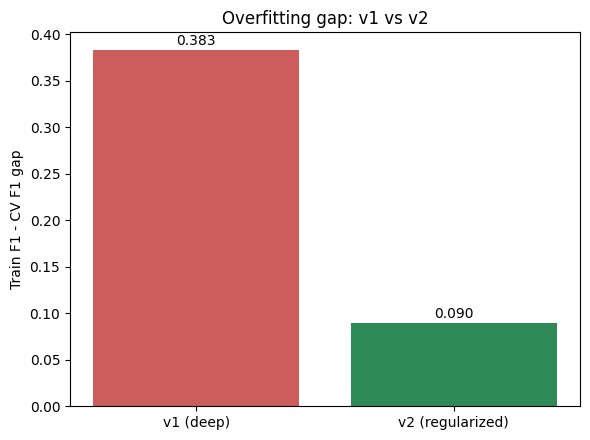

In [10]:
log_section('7. Generalization gap')

train_f1 = f1_score(y_train_i, best_model.predict(X_train))
cv_f1 = search.best_score_
print(f'Train F1 (full train) : {train_f1:.4f}')
print(f'CV F1 (TimeSeriesSplit): {cv_f1:.4f}')
print(f'Train - CV gap         : {train_f1 - cv_f1:.4f}')
print('v1 reference           : train 1.0000 / CV 0.6173 / gap 0.3827')

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.bar(['v1 (deep)', 'v2 (regularized)'], [0.3827, train_f1 - cv_f1],
       color=['indianred', 'seagreen'])
ax.set_ylabel('Train F1 - CV F1 gap'); ax.set_title('Overfitting gap: v1 vs v2')
for i, v in enumerate([0.3827, train_f1 - cv_f1]):
    ax.text(i, v + 0.005, f'{v:.3f}', ha='center')
plt.tight_layout()
save_fig('v2_01_generalization_gap', fig)
plt.show()

## 8. Early-stopping check

Independent confirmation of the right model size: fit on a chronological 85% refit slice and
early-stop on the latest 15% validation tail. `best_iteration` is the data-chosen tree count;
if it is well below `n_estimators`, the search's tree count was generous.

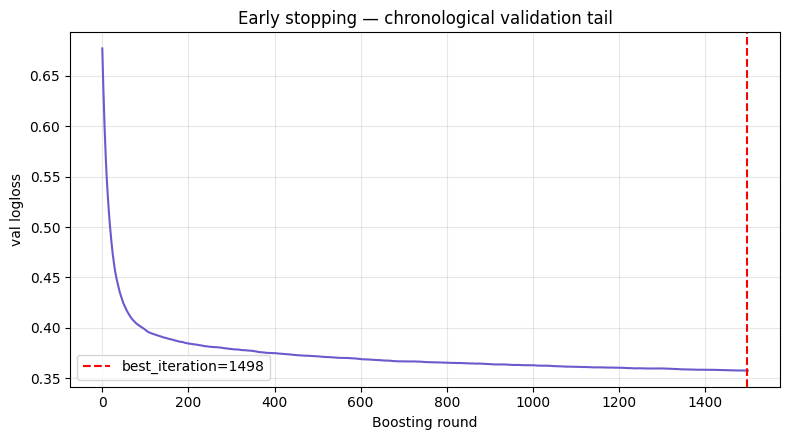

In [11]:
log_section('8. Early-stopping check')

n_train = len(X_train)
cut = int(n_train * 0.85)
X_rf, y_rf = X_train.iloc[:cut], y_train_i.iloc[:cut]
X_es, y_es = X_train.iloc[cut:], y_train_i.iloc[cut:]

es_params = {k: v for k, v in best_params.items() if k != 'n_estimators'}
try:
    es_model = make_xgb(n_estimators=1500, early_stopping_rounds=50, **es_params)
    es_model.fit(X_rf, y_rf, eval_set=[(X_es, y_es)], verbose=False)
    best_iter = es_model.best_iteration
    print(f'Early-stopping best_iteration: {best_iter} (cap 1500)')
    print(f'Search-selected n_estimators : {best_params.get("n_estimators")}')

    res = es_model.evals_result()
    metric = list(res['validation_0'].keys())[0]
    curve = res['validation_0'][metric]
    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.plot(curve, color='slateblue')
    ax.axvline(best_iter, color='red', linestyle='--', label=f'best_iteration={best_iter}')
    ax.set_xlabel('Boosting round'); ax.set_ylabel(f'val {metric}')
    ax.set_title('Early stopping — chronological validation tail')
    ax.legend(); ax.grid(alpha=0.3)
    plt.tight_layout()
    save_fig('v2_02_early_stopping_curve', fig)
    plt.show()
except Exception as e:
    print(f'Early-stopping check skipped ({type(e).__name__}: {e}).')

## 9. Threshold selection (TimeSeriesSplit CV)
Same PR-crossover criterion and [0.10, 0.80] grid as v1.

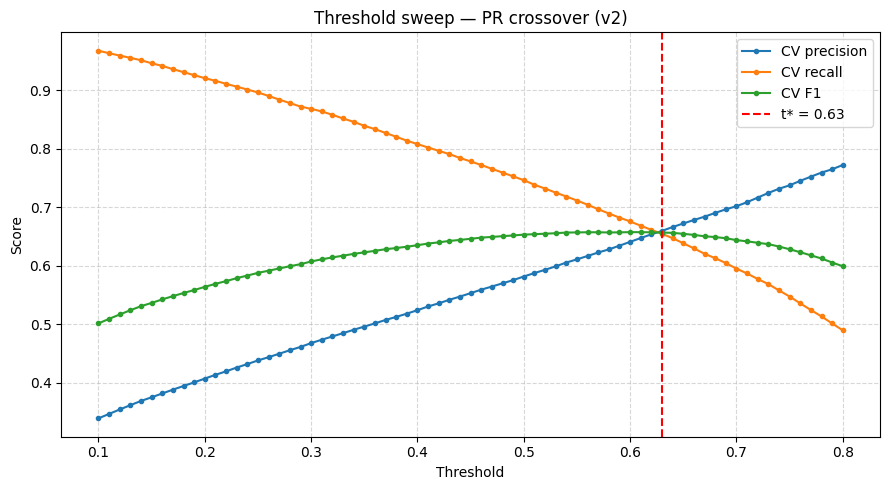

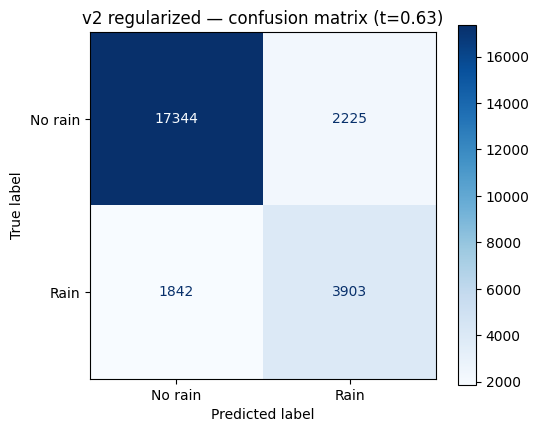

In [12]:
log_section('9. Threshold selection (TimeSeriesSplit CV)')

thresholds = np.round(np.arange(0.10, 0.81, 0.01), 2)
fold_records = []
for tr_idx, val_idx in ts_cv.split(X_train):
    fm = XGBClassifier(**best_model.get_params())
    fm.fit(X_train.iloc[tr_idx], y_train_i.iloc[tr_idx])
    fold_records.append((y_train_i.iloc[val_idx].values,
                         fm.predict_proba(X_train.iloc[val_idx])[:, 1]))

rows = []
for t in thresholds:
    f1s = [f1_score(yt, yp >= t) for yt, yp in fold_records]
    pr = [precision_score(yt, yp >= t, zero_division=0) for yt, yp in fold_records]
    rc = [recall_score(yt, yp >= t) for yt, yp in fold_records]
    rows.append({'threshold': t, 'CV_F1_mean': np.mean(f1s),
                 'CV_precision': np.mean(pr), 'CV_recall': np.mean(rc)})
thresh_df = pd.DataFrame(rows)
thresh_df['diff'] = (abs(thresh_df['CV_precision'] - thresh_df['CV_F1_mean'])
                     + abs(thresh_df['CV_F1_mean'] - thresh_df['CV_recall']))
best_threshold = float(thresh_df.loc[thresh_df['diff'].idxmin(), 'threshold'])
print(f'CV-selected threshold: {best_threshold}')
print(thresh_df.iloc[::5].to_string(index=False, float_format='%.4f'))

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(thresh_df['threshold'], thresh_df['CV_precision'], 'o-', label='CV precision', ms=3)
ax.plot(thresh_df['threshold'], thresh_df['CV_recall'], 'o-', label='CV recall', ms=3)
ax.plot(thresh_df['threshold'], thresh_df['CV_F1_mean'], 'o-', label='CV F1', ms=3)
ax.axvline(best_threshold, color='red', linestyle='--', label=f't* = {best_threshold}')
ax.set_xlabel('Threshold'); ax.set_ylabel('Score')
ax.set_title('Threshold sweep — PR crossover (v2)')
ax.legend(); ax.grid(linestyle='--', alpha=0.5)
plt.tight_layout()
save_fig('v2_03_threshold_sweep', fig)
plt.show()

y_pred_thr = (y_proba_tuned >= best_threshold).astype(int)
print(f'\nTest evaluation at threshold {best_threshold}:')
print(classification_report(y_test_i, y_pred_thr))

fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay(confusion_matrix(y_test_i, y_pred_thr),
                       display_labels=['No rain', 'Rain']).plot(cmap='Blues', ax=ax)
ax.set_title(f'v2 regularized — confusion matrix (t={best_threshold})')
plt.tight_layout()
save_fig('v2_04_confusion_matrix', fig)
plt.show()

## 10. Feature importance & SHAP — did the diff features get used?
Check whether `Pressure_diff` / `Temp_diff` rank above the raw pairs they summarize.

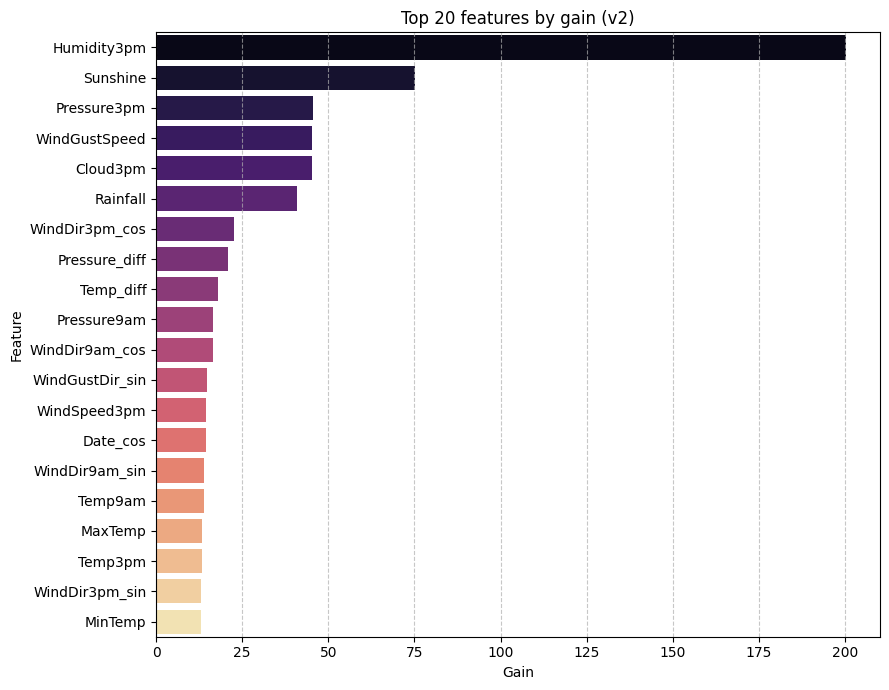

In [13]:
log_section('10. Feature importance & SHAP')

gain = best_model.get_booster().get_score(importance_type='gain')
imp_df = (pd.DataFrame({'Feature': list(gain.keys()), 'Gain': list(gain.values())})
          .sort_values('Gain', ascending=False).reset_index(drop=True))
print('Feature importance by gain (top 20):')
print(imp_df.head(20).to_string(index=False, float_format='%.2f'))
for f in ['Pressure_diff', 'Temp_diff']:
    if f in imp_df['Feature'].values:
        rank = int(imp_df.index[imp_df['Feature'] == f][0]) + 1
        print(f'  {f}: gain rank {rank}/{len(imp_df)}')

fig = plt.figure(figsize=(9, 7))
sns.barplot(data=imp_df.head(20), x='Gain', y='Feature',
            hue='Feature', palette='magma', legend=False)
plt.title('Top 20 features by gain (v2)'); plt.xlabel('Gain')
plt.grid(axis='x', linestyle='--', alpha=0.7); plt.tight_layout()
save_fig('v2_05_feature_importance_gain', fig)
plt.show()

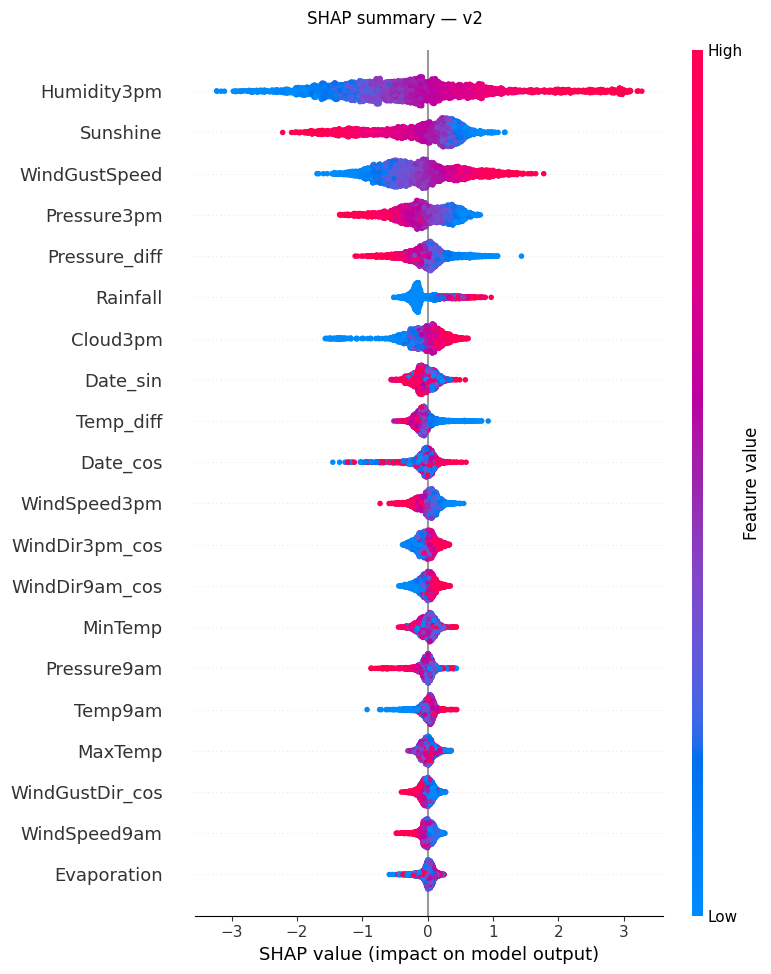

In [14]:
if HAS_SHAP:
    try:
        n_shap = min(3000, X_test.shape[0])
        X_shap = X_test.sample(n=n_shap, random_state=RANDOM_STATE)
        explainer = shap.TreeExplainer(best_model)
        shap_values = explainer.shap_values(X_shap)
        plt.figure()
        shap.summary_plot(shap_values, X_shap, show=False)
        fig = plt.gcf(); fig.suptitle('SHAP summary — v2', y=1.02)
        save_fig('v2_06_shap_summary', fig)
        plt.show()
        mean_abs = (pd.DataFrame({'Feature': X_shap.columns,
                                  'mean_abs_SHAP': np.abs(shap_values).mean(axis=0)})
                    .sort_values('mean_abs_SHAP', ascending=False))
        print('\nMean |SHAP| ranking (top 15):')
        print(mean_abs.head(15).to_string(index=False, float_format='%.4f'))
    except Exception as e:
        print(f'SHAP failed ({type(e).__name__}: {e}); skipping.')
else:
    print('SHAP not installed — gain importance only.')

## 11. Calibration & post-hoc recalibration
Same machinery as v1.

In [15]:
log_section('11. Calibration analysis')

def expected_calibration_error(y_true, y_prob, n_bins=10):
    edges = np.linspace(0, 1, n_bins + 1)
    bi = np.digitize(y_prob, edges[1:-1])
    ece, n = 0.0, len(y_true)
    for b in range(n_bins):
        m = bi == b
        if m.sum() > 0:
            ece += (m.sum() / n) * abs(y_true[m].mean() - y_prob[m].mean())
    return ece

calib = [{'model': 'regularized (tuned)',
          'Brier': brier_score_loss(y_test_i, y_proba_tuned),
          'logloss': log_loss(y_test_i, np.clip(y_proba_tuned, 1e-9, 1 - 1e-9)),
          'ECE_10': expected_calibration_error(y_test_i.values, y_proba_tuned, 10),
          'mean_pred': float(np.mean(y_proba_tuned)),
          'empirical_rate': float(y_test_i.mean())}]
print(pd.DataFrame(calib).round(4).to_string(index=False))

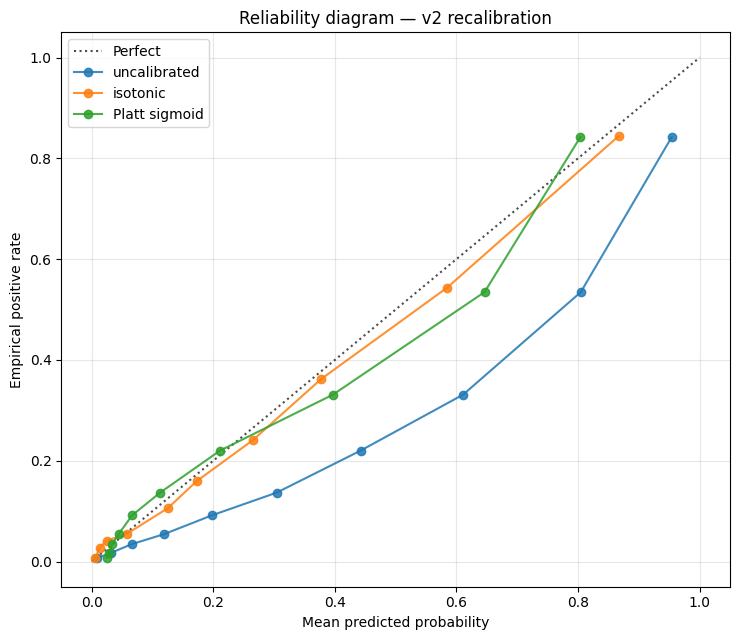

In [16]:
# Post-hoc recalibration on a chronological 85/15 refit/calibration split.
refit_model = XGBClassifier(**best_model.get_params())
refit_model.fit(X_rf, y_rf)

def make_calibrated(model, method, Xc, yc):
    try:
        from sklearn.frozen import FrozenEstimator
        cc = CalibratedClassifierCV(FrozenEstimator(model), method=method)
    except Exception:
        cc = CalibratedClassifierCV(model, method=method, cv='prefit')
    cc.fit(Xc, yc); return cc

calib_iso = make_calibrated(refit_model, 'isotonic', X_es, y_es)
calib_sig = make_calibrated(refit_model, 'sigmoid', X_es, y_es)
y_proba_iso = calib_iso.predict_proba(X_test)[:, 1]
y_proba_sig = calib_sig.predict_proba(X_test)[:, 1]

rows = []
for name, p in [('refit (uncalibrated)', refit_model.predict_proba(X_test)[:, 1]),
                ('isotonic recalibrated', y_proba_iso),
                ('sigmoid (Platt) recalibrated', y_proba_sig)]:
    rows.append({'method': name, 'Brier': brier_score_loss(y_test_i, p),
                 'logloss': log_loss(y_test_i, np.clip(p, 1e-9, 1 - 1e-9)),
                 'ECE_10': expected_calibration_error(y_test_i.values, p, 10),
                 'mean_pred': float(np.mean(p)), 'ROC_AUC': roc_auc_score(y_test_i, p)})
print('\nPost-hoc recalibration metrics:')
print(pd.DataFrame(rows).round(4).to_string(index=False))

fig, ax = plt.subplots(figsize=(7.5, 6.5))
ax.plot([0, 1], [0, 1], 'k:', alpha=0.7, label='Perfect')
for name, p in [('uncalibrated', refit_model.predict_proba(X_test)[:, 1]),
                ('isotonic', y_proba_iso), ('Platt sigmoid', y_proba_sig)]:
    pt, pp = calibration_curve(y_test_i, p, n_bins=10, strategy='quantile')
    ax.plot(pp, pt, 'o-', label=name, alpha=0.85)
ax.set_xlabel('Mean predicted probability'); ax.set_ylabel('Empirical positive rate')
ax.set_title('Reliability diagram — v2 recalibration')
ax.legend(loc='upper left'); ax.grid(alpha=0.3); plt.tight_layout()
save_fig('v2_07_recalibration_reliability_diagram', fig)
plt.show()

## 12. Final evaluation curves + learning curve
The learning curve is the headline check: does the train F1 line drop off 1.0?

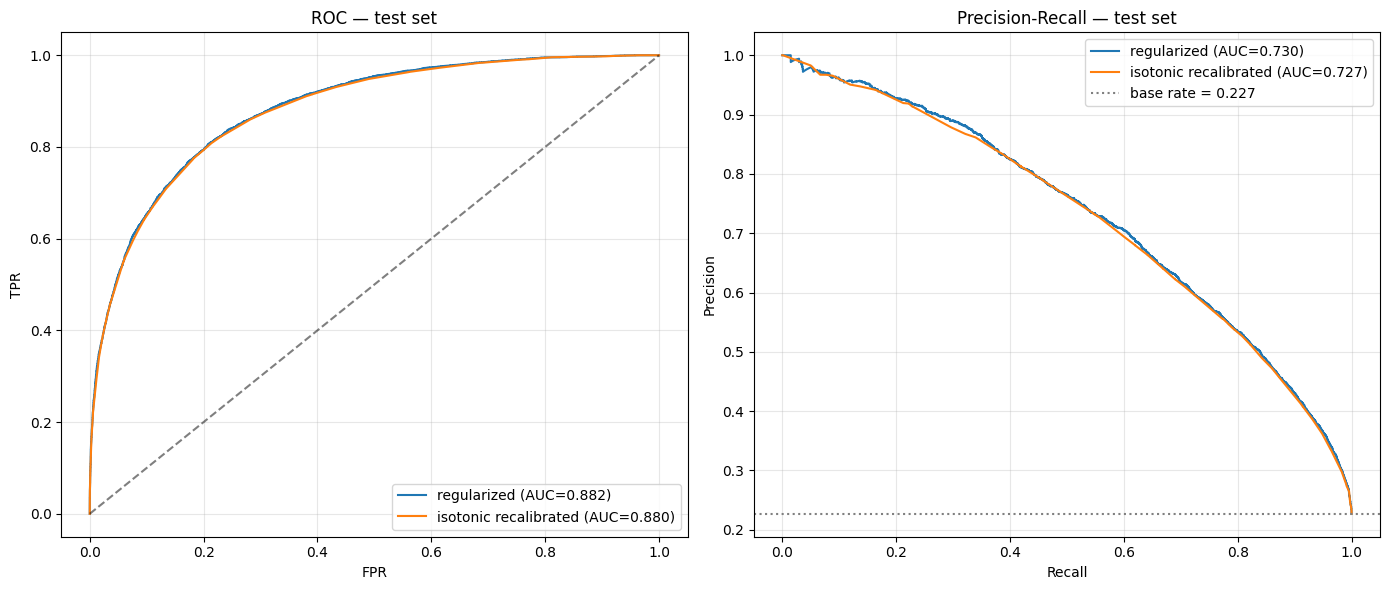

In [17]:
log_section('12. Final evaluation curves')

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
roc_aucs, pr_aucs = {}, {}
base_rate = float(y_test_i.mean())
for name, p in [('regularized', y_proba_tuned), ('isotonic recalibrated', y_proba_iso)]:
    fpr, tpr, _ = roc_curve(y_test_i, p); roc_aucs[name] = roc_auc_score(y_test_i, p)
    axes[0].plot(fpr, tpr, label=f'{name} (AUC={roc_aucs[name]:.3f})')
    pr, rc, _ = precision_recall_curve(y_test_i, p); pr_aucs[name] = auc(rc, pr)
    axes[1].plot(rc, pr, label=f'{name} (AUC={pr_aucs[name]:.3f})')
axes[0].plot([0, 1], [0, 1], 'k--', alpha=0.5); axes[0].set_title('ROC — test set')
axes[0].set_xlabel('FPR'); axes[0].set_ylabel('TPR'); axes[0].legend(loc='lower right'); axes[0].grid(alpha=0.3)
axes[1].axhline(base_rate, color='gray', linestyle=':', label=f'base rate = {base_rate:.3f}')
axes[1].set_title('Precision-Recall — test set'); axes[1].set_xlabel('Recall'); axes[1].set_ylabel('Precision')
axes[1].legend(loc='upper right'); axes[1].grid(alpha=0.3)
plt.tight_layout(); save_fig('v2_08_roc_pr_curves', fig); plt.show()

print('ROC-AUC:', {k: round(v, 4) for k, v in roc_aucs.items()})
print('PR-AUC :', {k: round(v, 4) for k, v in pr_aucs.items()})

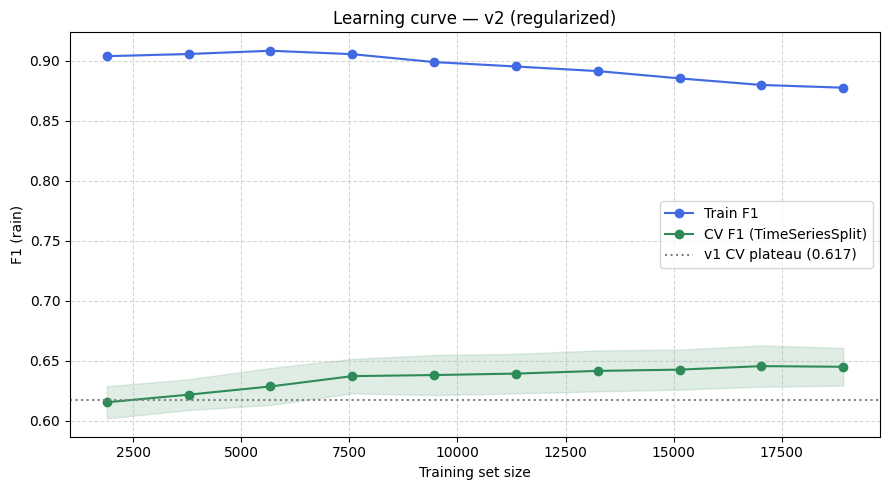

In [18]:
estimator = XGBClassifier(**best_model.get_params())
train_sizes, tr_sc, vl_sc = learning_curve(
    estimator, X_train, y_train_i, cv=ts_cv, scoring='f1',
    n_jobs=SEARCH_N_JOBS, train_sizes=np.linspace(0.1, 1.0, 10))
tr_m, tr_s = tr_sc.mean(1), tr_sc.std(1)
vl_m, vl_s = vl_sc.mean(1), vl_sc.std(1)
print('\nLearning curve — train vs CV F1:')
print(pd.DataFrame({'train_size': train_sizes, 'train_F1': tr_m, 'cv_F1': vl_m})
      .to_string(index=False, float_format='%.4f'))

fig = plt.figure(figsize=(9, 5))
plt.plot(train_sizes, tr_m, 'o-', color='royalblue', label='Train F1')
plt.fill_between(train_sizes, tr_m - tr_s, tr_m + tr_s, alpha=0.15, color='royalblue')
plt.plot(train_sizes, vl_m, 'o-', color='seagreen', label='CV F1 (TimeSeriesSplit)')
plt.fill_between(train_sizes, vl_m - vl_s, vl_m + vl_s, alpha=0.15, color='seagreen')
plt.axhline(0.617, color='gray', linestyle=':', label='v1 CV plateau (0.617)')
plt.xlabel('Training set size'); plt.ylabel('F1 (rain)')
plt.title('Learning curve — v2 (regularized)')
plt.legend(); plt.grid(linestyle='--', alpha=0.5); plt.tight_layout()
save_fig('v2_09_learning_curve', fig)
plt.show()

## Finalization

In [20]:
log_section('Finalization')

print(f'Results file: {_XGB2_RESULT_PATH}')
fig_files = sorted(f for f in os.listdir('figures') if f.startswith('v2_') and f.endswith('.png'))
print(f'v2 figures saved ({len(fig_files)}):')
for f in fig_files:
    print(f'  figures/{f}')

sys.stdout = _ORIG_STDOUT
_XGB2_RESULT_FILE.close()

ZIP_PATH = 'XGBoost_v2_artifacts.zip'
with zipfile.ZipFile(ZIP_PATH, 'w', zipfile.ZIP_DEFLATED) as zf:
    zf.write(_XGB2_RESULT_PATH)
    for f in fig_files:
        zf.write(f'figures/{f}')
print(f'Bundled artifacts into {ZIP_PATH}')

if IN_COLAB:
    from google.colab import files
    files.download(ZIP_PATH)
print(f'\nDone. See {_XGB2_RESULT_PATH} and figures/ (v2_*) for outputs.')


Finalization
Results file: XGB2_result.txt
v2 figures saved (9):
  figures/v2_01_generalization_gap.png
  figures/v2_02_early_stopping_curve.png
  figures/v2_03_threshold_sweep.png
  figures/v2_04_confusion_matrix.png
  figures/v2_05_feature_importance_gain.png
  figures/v2_06_shap_summary.png
  figures/v2_07_recalibration_reliability_diagram.png
  figures/v2_08_roc_pr_curves.png
  figures/v2_09_learning_curve.png
Bundled artifacts into XGBoost_v2_artifacts.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


Done. See XGB2_result.txt and figures/ (v2_*) for outputs.
